# Customer Purchase Prediction - E-Commerce (Models Built From Scratch)

**Goal:** predict whether an online-shopping session ends in a purchase (`Revenue = True`) from browsing behaviour.

**Dataset:** *Online Shoppers Purchasing Intention* (12,330 sessions, 15.5 % purchases).

**What is new in this version:** all four classifiers - **Logistic Regression, Decision Tree, K-Nearest Neighbours and Support Vector Machine** - are implemented from scratch with **NumPy only**. The same code lives in `scratch_ml.py` (used by `train_models.py` and the Streamlit app). scikit-learn is used in *one* place only: Section 8 compares our implementations against it as a correctness check.

**Evaluation protocol (no test-set leakage)**
1. Remove duplicates -> stratified 80:20 split.
2. Scaling / encoding statistics learned on the training part only.
3. Hyper-parameters **and** the decision threshold are chosen with 5-fold stratified cross-validation on the training part.
4. The untouched test set is used once, for the final numbers.

## 0. Imports

In [1]:
import numpy as np
import pandas as pd
from itertools import product

SEED = 42
MONTH_ORDER = ["Jan", "Feb", "Mar", "Apr", "May", "June", "Jul", "Aug", "Sep", "Oct", "Nov", "Dec"]
NUMERIC_COLS = ["Administrative", "Informational", "ProductRelated", "ProductRelated_Duration",
                "BounceRates", "ExitRates", "PageValues", "SpecialDay"]
LOG_COLS = ["Administrative", "Informational", "ProductRelated", "ProductRelated_Duration", "PageValues"]
RAW_FEATURES = NUMERIC_COLS + ["Month", "VisitorType", "Weekend"]
TARGET = "Revenue"

import matplotlib.pyplot as plt
import seaborn as sns
import warnings
warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid", palette="muted")
plt.rcParams["figure.figsize"] = (9, 5)
pd.set_option("display.width", 140)

CSV_PATH = "online_shoppers_intention.csv"   # keep the CSV next to this notebook

## 1. Data loading & cleaning
Missing values and exact duplicate sessions are removed (duplicates would otherwise appear in both train and test and inflate the scores).

In [2]:
def load_and_clean(path):
    """Read the CSV, drop rows with missing values and exact duplicate sessions."""
    raw = pd.read_csv(path)
    n_raw = len(raw)
    df = raw.dropna()
    n_missing = n_raw - len(df)
    df = df.drop_duplicates()
    n_dup = n_raw - n_missing - len(df)
    df = df.reset_index(drop=True)
    info = {"rows_raw": n_raw, "rows_missing": n_missing,
            "rows_duplicate": n_dup, "rows_clean": len(df)}
    return df, info

df, info = load_and_clean(CSV_PATH)
print(info)
print("Shape after cleaning:", df.shape)
display(df.head())
display(df.describe().T.round(2))

{'rows_raw': 12330, 'rows_missing': 0, 'rows_duplicate': 125, 'rows_clean': 12205}
Shape after cleaning: (12205, 18)


,Administrative,Administrative_Duration,Informational,Informational_Duration,ProductRelated,ProductRelated_Duration,BounceRates,ExitRates,PageValues,SpecialDay,Month,OperatingSystems,Browser,Region,TrafficType,VisitorType,Weekend,Revenue
0,0,0.0,0,0.0,1,0.000000,0.20,0.20,0.0,0.0,Feb,1,1,1,1,Returning_Visitor,False,False
1,0,0.0,0,0.0,2,64.000000,0.00,0.10,0.0,0.0,Feb,2,2,1,2,Returning_Visitor,False,False
2,0,0.0,0,0.0,1,0.000000,0.20,0.20,0.0,0.0,Feb,4,1,9,3,Returning_Visitor,False,False
3,0,0.0,0,0.0,2,2.666667,0.05,0.14,0.0,0.0,Feb,3,2,2,4,Returning_Visitor,False,False
4,0,0.0,0,0.0,10,627.500000,0.02,0.05,0.0,0.0,Feb,3,3,1,4,Returning_Visitor,True,False


,count,mean,std,min,25%,50%,75%,max
Administrative,12205.0,2.34,3.33,0.0,0.00,1.00,4.00,27.00
Administrative_Duration,12205.0,81.65,177.49,0.0,0.00,9.00,94.70,3398.75
Informational,12205.0,0.51,1.28,0.0,0.00,0.00,0.00,24.00
Informational_Duration,12205.0,34.83,141.42,0.0,0.00,0.00,0.00,2549.38
ProductRelated,12205.0,32.05,44.59,0.0,8.00,18.00,38.00,705.00
ProductRelated_Duration,12205.0,1206.98,1919.60,0.0,193.00,608.94,1477.15,63973.52
BounceRates,12205.0,0.02,0.05,0.0,0.00,0.00,0.02,0.20
ExitRates,12205.0,0.04,0.05,0.0,0.01,0.02,0.05,0.20
PageValues,12205.0,5.95,18.65,0.0,0.00,0.00,0.00,361.76
SpecialDay,12205.0,0.06,0.20,0.0,0.00,0.00,0.00,1.00


## 2. Exploratory data analysis

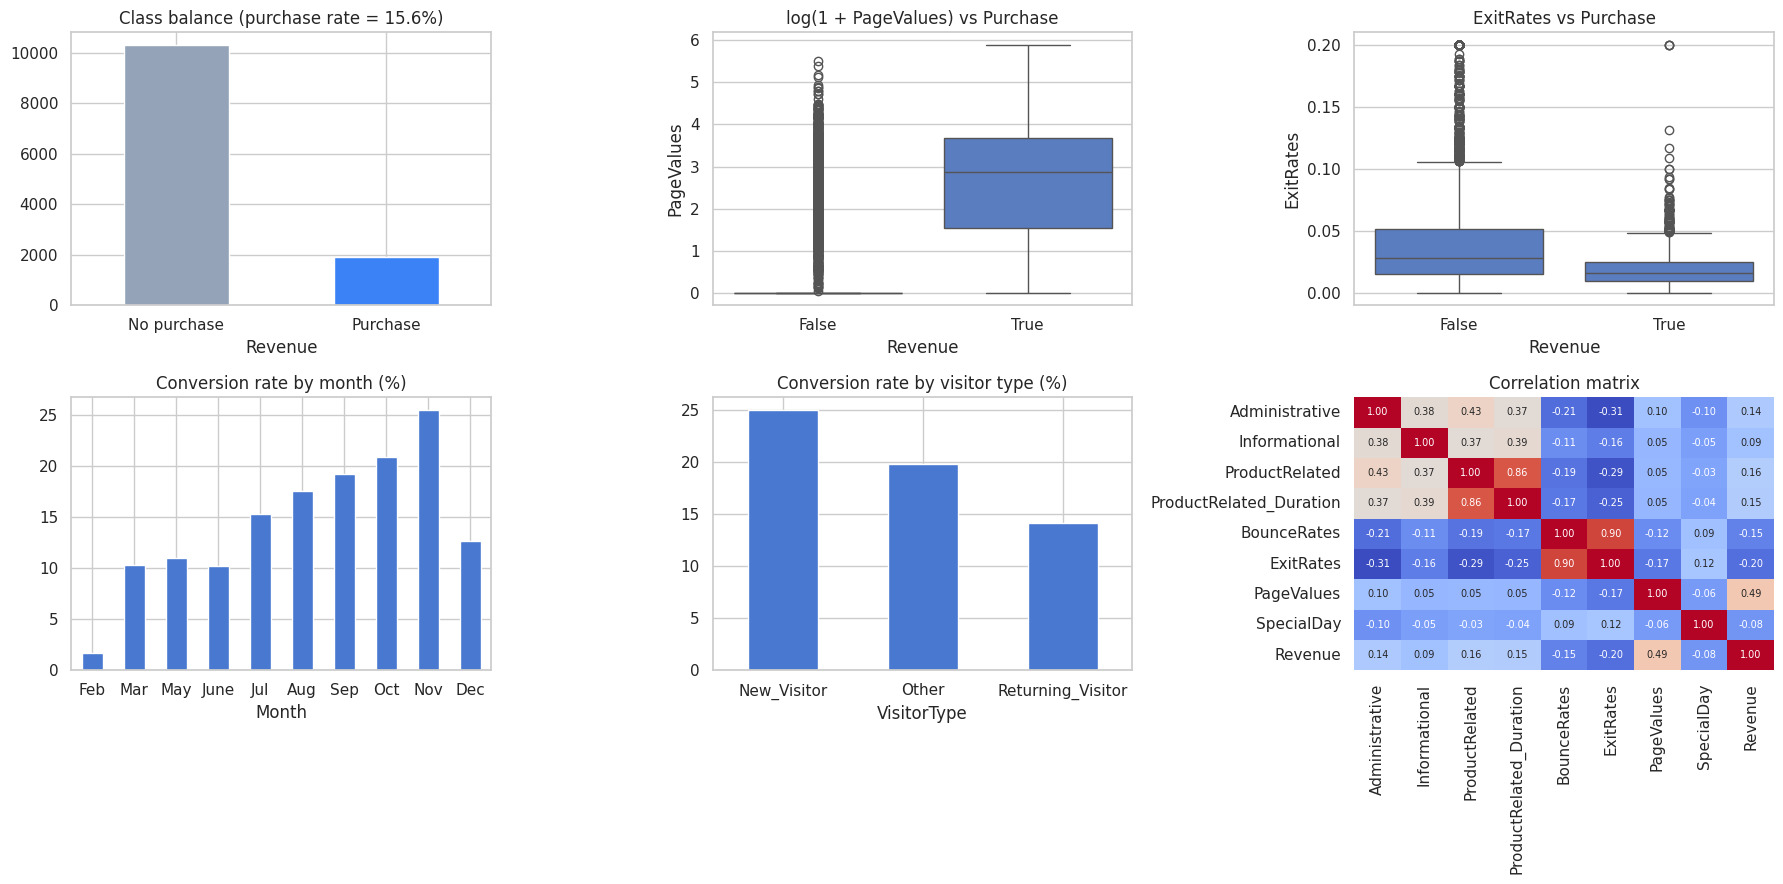

In [3]:
fig, ax = plt.subplots(2, 3, figsize=(18, 9))

# class balance
df[TARGET].value_counts().rename({False: "No purchase", True: "Purchase"}).plot.bar(ax=ax[0, 0], color=["#94A3B8", "#3B82F6"], rot=0)
ax[0, 0].set_title(f"Class balance (purchase rate = {df[TARGET].mean():.1%})")

# strongest single feature
sns.boxplot(x=TARGET, y=np.log1p(df["PageValues"]), data=df, ax=ax[0, 1])
ax[0, 1].set_title("log(1 + PageValues) vs Purchase")

sns.boxplot(x=TARGET, y="ExitRates", data=df, ax=ax[0, 2])
ax[0, 2].set_title("ExitRates vs Purchase")

# conversion by month / visitor type / weekend
(df.groupby("Month")[TARGET].mean().reindex([m for m in MONTH_ORDER if m in set(df["Month"])]) * 100).plot.bar(ax=ax[1, 0], rot=0)
ax[1, 0].set_title("Conversion rate by month (%)")
(df.groupby("VisitorType")[TARGET].mean() * 100).plot.bar(ax=ax[1, 1], rot=0)
ax[1, 1].set_title("Conversion rate by visitor type (%)")

corr = df[NUMERIC_COLS + [TARGET]].astype(float).corr()
sns.heatmap(corr, annot=True, fmt=".2f", cmap="coolwarm", ax=ax[1, 2], annot_kws={"size": 7}, cbar=False)
ax[1, 2].set_title("Correlation matrix")
plt.tight_layout(); plt.show()

**Take-aways:** the data is imbalanced (~84 % no purchase), so *accuracy alone is misleading* - a model that always predicts "no purchase" already scores ~84 %. `PageValues` is by far the strongest signal, `ExitRates`/`BounceRates` push the other way, November has the highest conversion and returning visitors convert less than new ones. Counts and durations are very right-skewed, which motivates the log transform below.

## 3. Preprocessing & train/test split
* `log(1+x)` on skewed count/duration columns, then standardisation (train statistics only)
* one-hot encoding of `Month` and `VisitorType` (label encoding would create a fake ordering that distorts distance-based models)
* stratified 80:20 split keeps the 15.6 % purchase rate in both parts

In [4]:
class Preprocessor:
    """
    Raw session record -> numeric feature vector.

    * heavily right-skewed count / duration columns get log(1 + x)
    * continuous columns are standardised with TRAIN mean / std only (no leakage)
    * Month and VisitorType are one-hot encoded (label encoding would impose a
      fake order, which hurts distance based models such as KNN / SVM / LR)
    * Weekend is a 0/1 flag
    """

    def fit(self, df):
        self.months_ = [m for m in MONTH_ORDER if m in set(df["Month"].astype(str))]
        self.visitors_ = sorted(df["VisitorType"].astype(str).unique())
        cont = self._continuous(df)
        self.mean_ = cont.mean(axis=0)
        self.std_ = cont.std(axis=0)
        self.std_[self.std_ == 0] = 1.0
        return self

    def _continuous(self, df):
        cont = df[NUMERIC_COLS].astype(float).copy()
        for c in LOG_COLS:
            cont[c] = np.log1p(cont[c])
        return cont.to_numpy()

    def transform(self, df):
        cont = (self._continuous(df) - self.mean_) / self.std_
        weekend = df["Weekend"].astype(int).to_numpy().reshape(-1, 1).astype(float)
        month = df["Month"].astype(str).to_numpy()
        visitor = df["VisitorType"].astype(str).to_numpy()
        month_oh = np.stack([(month == m).astype(float) for m in self.months_], axis=1)
        visitor_oh = np.stack([(visitor == v).astype(float) for v in self.visitors_], axis=1)
        return np.hstack([cont, weekend, month_oh, visitor_oh])

    def fit_transform(self, df):
        return self.fit(df).transform(df)

    @property
    def feature_names_(self):
        return (NUMERIC_COLS + ["Weekend"]
                + ["Month_" + m for m in self.months_]
                + ["Visitor_" + v for v in self.visitors_])

def stratified_split(y, test_size=0.20, seed=SEED):
    """Stratified train/test split (keeps the 15.5 % purchase rate in both parts)."""
    rng = np.random.RandomState(seed)
    y = np.asarray(y)
    train_idx, test_idx = [], []
    for c in np.unique(y):
        idx = np.where(y == c)[0]
        rng.shuffle(idx)
        n_test = int(round(len(idx) * test_size))
        test_idx.extend(idx[:n_test])
        train_idx.extend(idx[n_test:])
    return rng.permutation(train_idx), rng.permutation(test_idx)


def stratified_kfold(y, n_splits=5, seed=SEED):
    """Yield (train_idx, val_idx) pairs, each fold keeping the class ratio."""
    rng = np.random.RandomState(seed)
    y = np.asarray(y)
    folds = [[] for _ in range(n_splits)]
    for c in np.unique(y):
        idx = np.where(y == c)[0]
        rng.shuffle(idx)
        for k, part in enumerate(np.array_split(idx, n_splits)):
            folds[k].extend(part)
    for k in range(n_splits):
        val = np.array(folds[k])
        train = np.array([i for j in range(n_splits) if j != k for i in folds[j]])
        yield train, val

y = df[TARGET].astype(int).to_numpy()
train_idx, test_idx = stratified_split(y, test_size=0.20)

pre = Preprocessor().fit(df.iloc[train_idx])
X_train, X_test = pre.transform(df.iloc[train_idx]), pre.transform(df.iloc[test_idx])
y_train, y_test = y[train_idx], y[test_idx]

print("Features (%d):" % len(pre.feature_names_), pre.feature_names_)
print("Train:", X_train.shape, f"purchase rate {y_train.mean():.2%}")
print("Test :", X_test.shape, f"purchase rate {y_test.mean():.2%}")
print(f"Majority-class baseline accuracy on test: {1 - y_test.mean():.2%}")

Features (22): ['Administrative', 'Informational', 'ProductRelated', 'ProductRelated_Duration', 'BounceRates', 'ExitRates', 'PageValues', 'SpecialDay', 'Weekend', 'Month_Feb', 'Month_Mar', 'Month_May', 'Month_June', 'Month_Jul', 'Month_Aug', 'Month_Sep', 'Month_Oct', 'Month_Nov', 'Month_Dec', 'Visitor_New_Visitor', 'Visitor_Other', 'Visitor_Returning_Visitor']
Train: (9764, 22) purchase rate 15.63%
Test : (2441, 22) purchase rate 15.65%
Majority-class baseline accuracy on test: 84.35%


## 4. Evaluation metrics (from scratch)
Confusion matrix, accuracy, precision, recall, F1, ROC curve / AUC and an F1-optimal threshold search.

In [5]:
def confusion_matrix(y_true, y_pred):
    y_true = np.asarray(y_true).astype(int)
    y_pred = np.asarray(y_pred).astype(int)
    tn = int(((y_true == 0) & (y_pred == 0)).sum())
    fp = int(((y_true == 0) & (y_pred == 1)).sum())
    fn = int(((y_true == 1) & (y_pred == 0)).sum())
    tp = int(((y_true == 1) & (y_pred == 1)).sum())
    return np.array([[tn, fp], [fn, tp]])


def accuracy_score(y_true, y_pred):
    return float((np.asarray(y_true) == np.asarray(y_pred)).mean())


def precision_score(y_true, y_pred):
    (tn, fp), (fn, tp) = confusion_matrix(y_true, y_pred)
    return float(tp / (tp + fp)) if (tp + fp) else 0.0


def recall_score(y_true, y_pred):
    (tn, fp), (fn, tp) = confusion_matrix(y_true, y_pred)
    return float(tp / (tp + fn)) if (tp + fn) else 0.0


def f1_score(y_true, y_pred):
    p, r = precision_score(y_true, y_pred), recall_score(y_true, y_pred)
    return float(2 * p * r / (p + r)) if (p + r) else 0.0


def roc_curve(y_true, scores):
    """False-positive-rate / true-positive-rate pairs for every distinct score."""
    y = np.asarray(y_true).astype(int)
    s = np.asarray(scores, dtype=float)
    order = np.argsort(-s, kind="mergesort")
    s, y = s[order], y[order]
    tps, fps = np.cumsum(y), np.cumsum(1 - y)
    last = np.r_[np.where(np.diff(s))[0], len(y) - 1]
    tpr = np.r_[0.0, tps[last] / tps[-1]]
    fpr = np.r_[0.0, fps[last] / fps[-1]]
    return fpr, tpr


def roc_auc_score(y_true, scores):
    fpr, tpr = roc_curve(y_true, scores)
    return float(np.sum(np.diff(fpr) * (tpr[1:] + tpr[:-1]) / 2.0))


def best_f1_threshold(y_true, prob, grid=None):
    """Probability cut-off (searched on a 0.02..0.98 grid) that maximises F1."""
    grid = np.linspace(0.02, 0.98, 193) if grid is None else grid
    y = np.asarray(y_true).astype(bool)
    pred = np.asarray(prob)[:, None] >= grid[None, :]
    tp = (pred & y[:, None]).sum(axis=0)
    fp = (pred & ~y[:, None]).sum(axis=0)
    fn = y.sum() - tp
    f1 = 2 * tp / np.maximum(2 * tp + fp + fn, 1)
    best = np.flatnonzero(f1 >= f1.max() - 1e-12)
    j = best[len(best) // 2]                     # middle of the plateau = stable choice
    return float(grid[j]), float(f1[j])


def evaluate(y_true, prob, threshold=0.5):
    """All metrics for one model at a given decision threshold."""
    y_true = np.asarray(y_true).astype(int)
    y_pred = (np.asarray(prob) >= threshold).astype(int)
    cm = confusion_matrix(y_true, y_pred)
    tn, fp = cm[0]
    return {
        "Accuracy": accuracy_score(y_true, y_pred),
        "Precision": precision_score(y_true, y_pred),
        "Recall": recall_score(y_true, y_pred),
        "F1-Score": f1_score(y_true, y_pred),
        "Specificity": float(tn / (tn + fp)) if (tn + fp) else 0.0,
        "ROC-AUC": roc_auc_score(y_true, prob),
        "Confusion_Matrix": cm.tolist(),
        "Threshold": float(threshold),
    }

## 5. The four models, from scratch

| Model | Algorithm implemented |
|---|---|
| Logistic Regression | Newton-Raphson (IRLS) on the L2-regularised log-loss |
| Decision Tree | CART - exhaustive best split by Gini / Entropy gain, pre-pruning (depth, min samples) |
| KNN | vectorised Euclidean distances, uniform or 1/distance weighted vote |
| SVM | hinge loss + L2 margin, RBF kernel via Random Fourier Features, Adam sub-gradient descent, Platt scaling for probabilities |

All four share a tiny base class (`predict_proba`, `predict` using a tunable decision threshold).

In [6]:
def sigmoid(z):
    """Numerically stable logistic function."""
    z = np.asarray(z, dtype=float)
    out = np.empty_like(z)
    pos = z >= 0
    out[pos] = 1.0 / (1.0 + np.exp(-z[pos]))
    ez = np.exp(z[~pos])
    out[~pos] = ez / (1.0 + ez)
    return out


def platt_apply(scores, A, B):
    """Platt scaling: raw SVM margin -> probability."""
    return sigmoid(-(A * np.asarray(scores, dtype=float) + B))


def fit_platt(scores, y, max_iter=100):
    """Fit p = 1 / (1 + exp(A*s + B)) by Newton's method (Platt, 1999)."""
    s = np.asarray(scores, dtype=float)
    y = np.asarray(y).astype(int)
    n_pos, n_neg = y.sum(), (1 - y).sum()
    t = np.where(y == 1, (n_pos + 1.0) / (n_pos + 2.0), 1.0 / (n_neg + 2.0))
    A, B = 0.0, float(np.log((n_neg + 1.0) / (n_pos + 1.0)))

    def nll(a, b):
        z = a * s + b
        return float(np.sum(t * np.logaddexp(0, z) + (1 - t) * np.logaddexp(0, -z)))

    cur = nll(A, B)
    for _ in range(max_iter):
        p = platt_apply(s, A, B)
        g = np.array([np.sum((t - p) * s), np.sum(t - p)])
        w = p * (1 - p)
        H = np.array([[np.sum(s * s * w), np.sum(s * w)], [np.sum(s * w), np.sum(w)]]) + 1e-10 * np.eye(2)
        step = np.linalg.solve(H, g)
        scale = 1.0
        while scale > 1e-8:                       # backtracking line search
            new = nll(A - scale * step[0], B - scale * step[1])
            if new <= cur + 1e-12:
                break
            scale /= 2
        A, B = A - scale * step[0], B - scale * step[1]
        if abs(cur - new) < 1e-10:
            break
        cur = new
    return float(A), float(B)


class ClassifierMixin:
    """Shared predict / predict_proba logic. Subclasses implement fit() and score()."""
    threshold_ = 0.5
    platt_ = None

    def predict_proba(self, X):
        s = self.score(X)
        p = s if self.platt_ is None else platt_apply(s, *self.platt_)
        return np.column_stack([1 - p, p])

    def predict(self, X):
        return (self.predict_proba(X)[:, 1] >= self.threshold_).astype(int)

### 5.1 Logistic Regression

In [7]:
class LogisticRegressionScratch(ClassifierMixin):
    """
    L2-regularised logistic regression trained with Newton-Raphson (IRLS).

        minimise   sum_i log-loss_i  +  (l2 / 2) * ||w||^2        (bias not penalised)
        update     w <- w - H^-1 g,   g = X^T (p - y) + l2 w,   H = X^T S X + l2 I
    """

    def __init__(self, l2=1.0, max_iter=50, tol=1e-8):
        self.l2, self.max_iter, self.tol = l2, max_iter, tol

    def fit(self, X, y):
        X = np.asarray(X, dtype=float)
        y = np.asarray(y, dtype=float)
        Xb = np.hstack([np.ones((len(X), 1)), X])
        reg = self.l2 * np.eye(Xb.shape[1])
        reg[0, 0] = 0.0
        w = np.zeros(Xb.shape[1])
        for it in range(self.max_iter):
            p = sigmoid(Xb @ w)
            grad = Xb.T @ (p - y) + reg @ w
            hess = Xb.T @ (Xb * (p * (1 - p))[:, None]) + reg + 1e-10 * np.eye(len(w))
            step = np.linalg.solve(hess, grad)
            w -= step
            if np.max(np.abs(step)) < self.tol:
                break
        self.n_iter_ = it + 1
        self.bias_, self.coef_ = w[0], w[1:]
        return self

    def score(self, X):
        return sigmoid(np.asarray(X, dtype=float) @ self.coef_ + self.bias_)

### 5.2 Decision Tree (CART)

In [8]:
class _Node:
    __slots__ = ("feature", "threshold", "left", "right", "proba", "n_samples")

    def __init__(self):
        self.feature, self.threshold, self.left, self.right = -1, 0.0, None, None
        self.proba, self.n_samples = 0.0, 0


class DecisionTreeScratch(ClassifierMixin):
    """
    CART binary classification tree.

    At every node all features and all mid-point thresholds are scanned (vectorised with
    sorted cumulative class weights) and the split with the largest impurity decrease
    (Gini or Entropy) is taken. Growth is limited by max_depth, min_samples_split and
    min_samples_leaf (pre-pruning). Leaf probability = fraction of purchases in the leaf.
    """

    def __init__(self, criterion="gini", max_depth=5, min_samples_split=10,
                 min_samples_leaf=5, class_weight=None):
        self.criterion, self.max_depth = criterion, max_depth
        self.min_samples_split, self.min_samples_leaf = min_samples_split, min_samples_leaf
        self.class_weight = class_weight

    def _impurity(self, w0, w1):
        tot = np.maximum(w0 + w1, 1e-12)
        p0, p1 = w0 / tot, w1 / tot
        if self.criterion == "gini":
            return 1.0 - p0 ** 2 - p1 ** 2
        def xlog(p):
            return np.where(p > 0, p * np.log2(np.where(p > 0, p, 1.0)), 0.0)
        return -(xlog(p0) + xlog(p1))

    def _best_split(self, X, y, sw):
        n, d = X.shape
        w1, w0 = sw * y, sw * (1 - y)
        W1, W0 = w1.sum(), w0.sum()
        parent = self._impurity(W0, W1) * (W0 + W1)
        best, best_gain = None, 1e-12
        left_n = np.arange(1, n)
        for j in range(d):
            order = np.argsort(X[:, j], kind="mergesort")
            xs = X[order, j]
            if xs[0] == xs[-1]:
                continue
            l1, l0 = np.cumsum(w1[order])[:-1], np.cumsum(w0[order])[:-1]
            r1, r0 = W1 - l1, W0 - l0
            valid = ((xs[1:] > xs[:-1]) & (left_n >= self.min_samples_leaf)
                     & (n - left_n >= self.min_samples_leaf))
            if not valid.any():
                continue
            child = self._impurity(l0, l1) * (l0 + l1) + self._impurity(r0, r1) * (r0 + r1)
            gain = np.where(valid, parent - child, -np.inf)
            i = int(np.argmax(gain))
            if gain[i] > best_gain:
                best_gain, best = gain[i], (j, (xs[i] + xs[i + 1]) / 2.0)
        return best, best_gain

    def _build(self, X, y, sw, depth):
        node = _Node()
        node.n_samples, node.proba = len(y), float(y.mean())
        too_deep = self.max_depth is not None and depth >= self.max_depth
        if too_deep or len(y) < self.min_samples_split or y.min() == y.max():
            return node
        split, gain = self._best_split(X, y, sw)
        if split is None:
            return node
        j, t = split
        mask = X[:, j] <= t
        node.feature, node.threshold = j, t
        self.importances_[j] += gain
        node.left = self._build(X[mask], y[mask], sw[mask], depth + 1)
        node.right = self._build(X[~mask], y[~mask], sw[~mask], depth + 1)
        return node

    def fit(self, X, y):
        X = np.asarray(X, dtype=float)
        y = np.asarray(y).astype(float)
        sw = np.ones(len(y))
        if self.class_weight == "balanced":
            for c in (0.0, 1.0):
                sw[y == c] = len(y) / (2.0 * (y == c).sum())
        self.importances_ = np.zeros(X.shape[1])
        self.root_ = self._build(X, y, sw, 0)
        total = self.importances_.sum()
        if total > 0:
            self.importances_ = self.importances_ / total
        return self

    def _walk(self, node, X, idx, out):
        if node.left is None:
            out[idx] = node.proba
            return
        go_left = X[idx, node.feature] <= node.threshold
        self._walk(node.left, X, idx[go_left], out)
        self._walk(node.right, X, idx[~go_left], out)

    def score(self, X):
        X = np.asarray(X, dtype=float)
        out = np.zeros(len(X))
        self._walk(self.root_, X, np.arange(len(X)), out)
        return out

    def get_depth(self):
        def depth(n):
            return 0 if n.left is None else 1 + max(depth(n.left), depth(n.right))
        return depth(self.root_)

    def get_n_leaves(self):
        def leaves(n):
            return 1 if n.left is None else leaves(n.left) + leaves(n.right)
        return leaves(self.root_)

### 5.3 K-Nearest Neighbours

In [9]:
class KNNScratch(ClassifierMixin):
    """
    K-Nearest Neighbours. Euclidean distances are computed in vectorised chunks using
    ||a-b||^2 = ||a||^2 + ||b||^2 - 2 a.b ; the k closest training points vote
    (uniformly, or weighted by 1/distance).
    """

    def __init__(self, k=15, weights="uniform", chunk=512):
        self.k, self.weights, self.chunk = k, weights, chunk

    def fit(self, X, y):
        self.X_ = np.asarray(X, dtype=float)
        self.y_ = np.asarray(y, dtype=float)
        self.sq_ = (self.X_ ** 2).sum(axis=1)
        return self

    def score(self, X):
        X = np.asarray(X, dtype=float)
        k = min(self.k, len(self.X_))
        out = np.zeros(len(X))
        for s in range(0, len(X), self.chunk):
            xb = X[s:s + self.chunk]
            d2 = (xb ** 2).sum(axis=1)[:, None] + self.sq_[None, :] - 2.0 * xb @ self.X_.T
            np.maximum(d2, 0.0, out=d2)
            nn = np.argpartition(d2, k - 1, axis=1)[:, :k]
            labels = self.y_[nn]
            if self.weights == "distance":
                w = 1.0 / (np.sqrt(np.take_along_axis(d2, nn, axis=1)) + 1e-9)
                out[s:s + self.chunk] = (w * labels).sum(axis=1) / w.sum(axis=1)
            else:
                out[s:s + self.chunk] = labels.mean(axis=1)
        return out

### 5.4 Support Vector Machine
An *exact* kernel SVM needs an n x n kernel matrix (about 9,800 x 9,800 here) and an SMO solver, which is slow in pure Python. The RBF kernel is therefore approximated with **Random Fourier Features** (Rahimi & Recht, 2007) and the resulting linear SVM is solved on its primal objective. Section 8 shows this matches scikit-learn's exact-kernel `SVC` closely.

In [10]:
class SVMScratch(ClassifierMixin):
    """
    Soft-margin SVM trained directly on the primal objective

        min_{w,b}  1/(2 C n) ||w||^2  +  (1/n) sum_i  s_i * max(0, 1 - y_i (w.z_i + b))

    with full-batch sub-gradient descent (Adam step sizes).  For kernel='rbf' the inputs are
    first mapped with Random Fourier Features (Rahimi & Recht, 2007), z(x) = sqrt(2/D) cos(Wx+b),
    which satisfy z(x).z(x') ~ exp(-gamma ||x-x'||^2); the SVM is then linear in z-space.
    kernel='linear' trains on the raw features.  Probabilities come from Platt scaling.
    """

    def __init__(self, C=1.0, kernel="rbf", gamma=0.05, n_components=500, n_iter=300,
                 lr=0.05, class_weight=None, seed=SEED):
        self.C, self.kernel, self.gamma = C, kernel, gamma
        self.n_components, self.n_iter, self.lr = n_components, n_iter, lr
        self.class_weight, self.seed = class_weight, seed
        self.platt_ = (-1.0, 0.0)               # identity-like default (p = sigmoid(margin))

    def _map(self, X):
        X = np.asarray(X, dtype=float)
        if self.kernel == "linear":
            return X
        return np.sqrt(2.0 / self.n_components) * np.cos(X @ self.W_ + self.b_)

    def fit(self, X, y):
        X = np.asarray(X, dtype=float)
        y = np.asarray(y).astype(float)
        ys = 2.0 * y - 1.0
        if self.kernel == "rbf":
            rng = np.random.RandomState(self.seed)
            self.W_ = rng.normal(0.0, np.sqrt(2.0 * self.gamma), (X.shape[1], self.n_components))
            self.b_ = rng.uniform(0.0, 2.0 * np.pi, self.n_components)
        Z = self._map(X)
        n, D = Z.shape
        sw = np.ones(n)
        if self.class_weight == "balanced":
            for c in (0.0, 1.0):
                sw[y == c] = n / (2.0 * (y == c).sum())
        lam = 1.0 / (self.C * n)
        w, b = np.zeros(D), 0.0
        mw, vw, mb, vb = np.zeros(D), np.zeros(D), 0.0, 0.0
        b1, b2, eps = 0.9, 0.999, 1e-8
        w_avg, b_avg, n_avg = np.zeros(D), 0.0, 0
        for t in range(1, self.n_iter + 1):
            viol = ys * (Z @ w + b) < 1.0                       # margin violators
            coef = sw[viol] * ys[viol]
            gw = lam * w - (Z[viol].T @ coef) / n
            gb = -coef.sum() / n
            lr = self.lr / np.sqrt(t)
            mw, vw = b1 * mw + (1 - b1) * gw, b2 * vw + (1 - b2) * gw ** 2
            mb, vb = b1 * mb + (1 - b1) * gb, b2 * vb + (1 - b2) * gb ** 2
            w -= lr * (mw / (1 - b1 ** t)) / (np.sqrt(vw / (1 - b2 ** t)) + eps)
            b -= lr * (mb / (1 - b1 ** t)) / (np.sqrt(vb / (1 - b2 ** t)) + eps)
            if t > self.n_iter // 2:                            # average the 2nd half (less noise)
                w_avg, b_avg, n_avg = w_avg + w, b_avg + b, n_avg + 1
        self.w_, self.bias_ = w_avg / n_avg, b_avg / n_avg
        return self

    def score(self, X):                                         # raw signed margin
        return self._map(X) @ self.w_ + self.bias_

    decision_function = score

## 6. Hyper-parameter tuning + decision-threshold tuning
Because only 15.6 % of sessions are purchases, the default 0.5 cut-off makes every model too conservative (low recall). For each hyper-parameter candidate we therefore:
1. compute **out-of-fold** probabilities with 5-fold stratified CV (training data only),
2. pick the threshold that maximises F1 on those out-of-fold predictions,
3. keep the candidate with the best CV F1.

The test set plays no part in any of these choices.

In [11]:
def cross_val_scores(make_model, X, y, n_splits=5, seed=SEED):
    """Out-of-fold raw scores: every training row is scored by a model that never saw it."""
    oof = np.zeros(len(y))
    for tr, va in stratified_kfold(y, n_splits, seed):
        model = make_model()
        model.fit(X[tr], y[tr])
        oof[va] = model.score(X[va])
    return oof


def tune_model(model_cls, grid, X, y, fixed=None, platt=False, n_splits=5, verbose=True):
    """
    Grid search with stratified K-fold on the TRAINING data only.
    For each candidate: out-of-fold probabilities -> best-F1 threshold -> CV F1 / AUC.
    The candidate with the highest CV F1 wins (ties broken by AUC).
    """
    keys = list(grid)
    rows, best = [], None
    for values in product(*[grid[k] for k in keys]):
        params = dict(zip(keys, values))
        params.update(fixed or {})
        oof = cross_val_scores(lambda: model_cls(**params), X, y, n_splits)
        ab = fit_platt(oof, y) if platt else None
        prob = platt_apply(oof, *ab) if platt else oof
        thr, f1 = best_f1_threshold(y, prob)
        row = dict(params)
        row.update({"cv_f1": f1, "cv_auc": roc_auc_score(y, prob),
                    "cv_acc": accuracy_score(y, (prob >= thr).astype(int)), "threshold": thr})
        rows.append(row)
        if best is None or (f1, row["cv_auc"]) > (best["cv_f1"], best["cv_auc"]):
            best = dict(row, _params=params, _platt=ab)
        if verbose:
            print("   ", {k: params[k] for k in keys}, "-> CV F1=%.4f  AUC=%.4f" % (f1, row["cv_auc"]))
    table = pd.DataFrame(rows).sort_values(["cv_f1", "cv_auc"], ascending=False).reset_index(drop=True)
    return {"best_params": best["_params"], "threshold": best["threshold"],
            "platt": best["_platt"], "table": table}


def fit_final(model_cls, tuned, X, y):
    """Refit the winning configuration on the full training set and attach its threshold."""
    model = model_cls(**tuned["best_params"])
    model.fit(X, y)
    model.threshold_ = tuned["threshold"]
    if tuned["platt"] is not None:
        model.platt_ = tuned["platt"]
    return model

In [12]:
SPECS = {
    "Logistic Regression": dict(cls=LogisticRegressionScratch, platt=False,
        grid={"l2": [1.0, 10.0, 100.0, 300.0, 1000.0]}, fixed={}),
    "Decision Tree": dict(cls=DecisionTreeScratch, platt=False,
        grid={"criterion": ["gini", "entropy"], "max_depth": [3, 4, 5, 6, 8],
              "min_samples_leaf": [5, 10, 20], "class_weight": [None, "balanced"]},
        fixed={"min_samples_split": 10}),
    "K-Nearest Neighbors (KNN)": dict(cls=KNNScratch, platt=False,
        grid={"k": [11, 21, 31, 51, 71, 101], "weights": ["uniform", "distance"]}, fixed={}),
    "Support Vector Machine (SVM)": dict(cls=SVMScratch, platt=True,
        grid={"C": [0.3, 1.0, 3.0], "gamma": [0.05, 0.1], "class_weight": [None, "balanced"]},
        fixed={"kernel": "rbf", "n_components": 500, "n_iter": 300}),
}

tuned, models = {}, {}
for name, spec in SPECS.items():
    tuned[name] = tune_model(spec["cls"], spec["grid"], X_train, y_train,
                             fixed=spec["fixed"], platt=spec["platt"], verbose=False)
    models[name] = fit_final(spec["cls"], tuned[name], X_train, y_train)
    print(f"{name:30s} best = { {k: v for k, v in tuned[name]['best_params'].items() if k in spec['grid']} }"
          f"   threshold = {tuned[name]['threshold']:.3f}   CV F1 = {tuned[name]['table'].iloc[0]['cv_f1']:.4f}")

Logistic Regression            best = {'l2': 100.0}   threshold = 0.210   CV F1 = 0.6705


Decision Tree                  best = {'criterion': 'entropy', 'max_depth': 5, 'min_samples_leaf': 10, 'class_weight': 'balanced'}   threshold = 0.315   CV F1 = 0.6810


K-Nearest Neighbors (KNN)      best = {'k': 71, 'weights': 'distance'}   threshold = 0.360   CV F1 = 0.6739


Support Vector Machine (SVM)   best = {'C': 3.0, 'gamma': 0.1, 'class_weight': None}   threshold = 0.165   CV F1 = 0.6750


In [13]:
# Top candidates of every search (cross-validated, training data only)
for name in tuned:
    print("\n" + name)
    display(tuned[name]["table"].head(5).round(4))


Logistic Regression


,l2,cv_f1,cv_auc,cv_acc,threshold
0,100.0,0.6705,0.9115,0.8837,0.210
1,10.0,0.6699,0.9134,0.8943,0.325
2,1.0,0.6697,0.9135,0.8947,0.325
3,300.0,0.6680,0.9077,0.8788,0.175
4,1000.0,0.6654,0.9000,0.8783,0.200



Decision Tree


,criterion,max_depth,min_samples_leaf,class_weight,min_samples_split,cv_f1,cv_auc,cv_acc,threshold
0,entropy,5,10,balanced,10,0.6810,0.9190,0.8938,0.315
1,entropy,5,20,balanced,10,0.6809,0.9204,0.8978,0.360
2,entropy,5,5,balanced,10,0.6783,0.9158,0.8926,0.315
3,entropy,4,20,NaN,10,0.6778,0.9175,0.8952,0.350
4,entropy,4,5,NaN,10,0.6778,0.9174,0.8952,0.345



K-Nearest Neighbors (KNN)


,k,weights,cv_f1,cv_auc,cv_acc,threshold
0,71,distance,0.6739,0.9215,0.8921,0.360
1,51,distance,0.6731,0.9213,0.8891,0.335
2,31,distance,0.6715,0.9183,0.8847,0.310
3,51,uniform,0.6712,0.9200,0.8873,0.325
4,71,uniform,0.6710,0.9199,0.8909,0.360



Support Vector Machine (SVM)


,C,gamma,class_weight,kernel,n_components,n_iter,cv_f1,cv_auc,cv_acc,threshold
0,3.0,0.10,NaN,rbf,500,300,0.6750,0.9149,0.8908,0.165
1,1.0,0.05,NaN,rbf,500,300,0.6744,0.9092,0.8908,0.190
2,3.0,0.05,NaN,rbf,500,300,0.6743,0.9096,0.8861,0.140
3,1.0,0.05,balanced,rbf,500,300,0.6740,0.9179,0.8906,0.355
4,0.3,0.05,NaN,rbf,500,300,0.6739,0.9074,0.8885,0.170


## 7. Final evaluation on the untouched test set

In [14]:
prob = {n: m.predict_proba(X_test)[:, 1] for n, m in models.items()}

rows_default, rows_tuned = [], []
for n in models:
    d = evaluate(y_test, prob[n], 0.5)
    t = evaluate(y_test, prob[n], models[n].threshold_)
    rows_default.append({"Model": n, **{k: d[k] for k in ["Accuracy", "Precision", "Recall", "F1-Score", "ROC-AUC"]}})
    rows_tuned.append({"Model": n, "Threshold": models[n].threshold_,
                       **{k: t[k] for k in ["Accuracy", "Precision", "Recall", "F1-Score", "Specificity", "ROC-AUC"]}})

print("A) Default 0.5 threshold")
display(pd.DataFrame(rows_default).set_index("Model").round(4))
print("B) CV-tuned threshold  <- final reported results")
results_df = pd.DataFrame(rows_tuned).set_index("Model")
display(results_df.round(4))

A) Default 0.5 threshold


,Accuracy,Precision,Recall,F1-Score,ROC-AUC
Model,,,,,
Logistic Regression,0.8923,0.7117,0.5236,0.6033,0.9221
Decision Tree,0.8914,0.6594,0.6335,0.6462,0.9317
K-Nearest Neighbors (KNN),0.9013,0.7238,0.5969,0.6542,0.9313
Support Vector Machine (SVM),0.8968,0.7273,0.5445,0.6228,0.9261


B) CV-tuned threshold  <- final reported results


,Threshold,Accuracy,Precision,Recall,F1-Score,Specificity,ROC-AUC
Model,,,,,,,
Logistic Regression,0.210,0.8861,0.6032,0.7958,0.6862,0.9029,0.9221
Decision Tree,0.315,0.8959,0.6475,0.7356,0.6887,0.9257,0.9317
K-Nearest Neighbors (KNN),0.360,0.8914,0.6297,0.7435,0.6819,0.9189,0.9313
Support Vector Machine (SVM),0.165,0.8914,0.6286,0.7487,0.6834,0.9179,0.9261


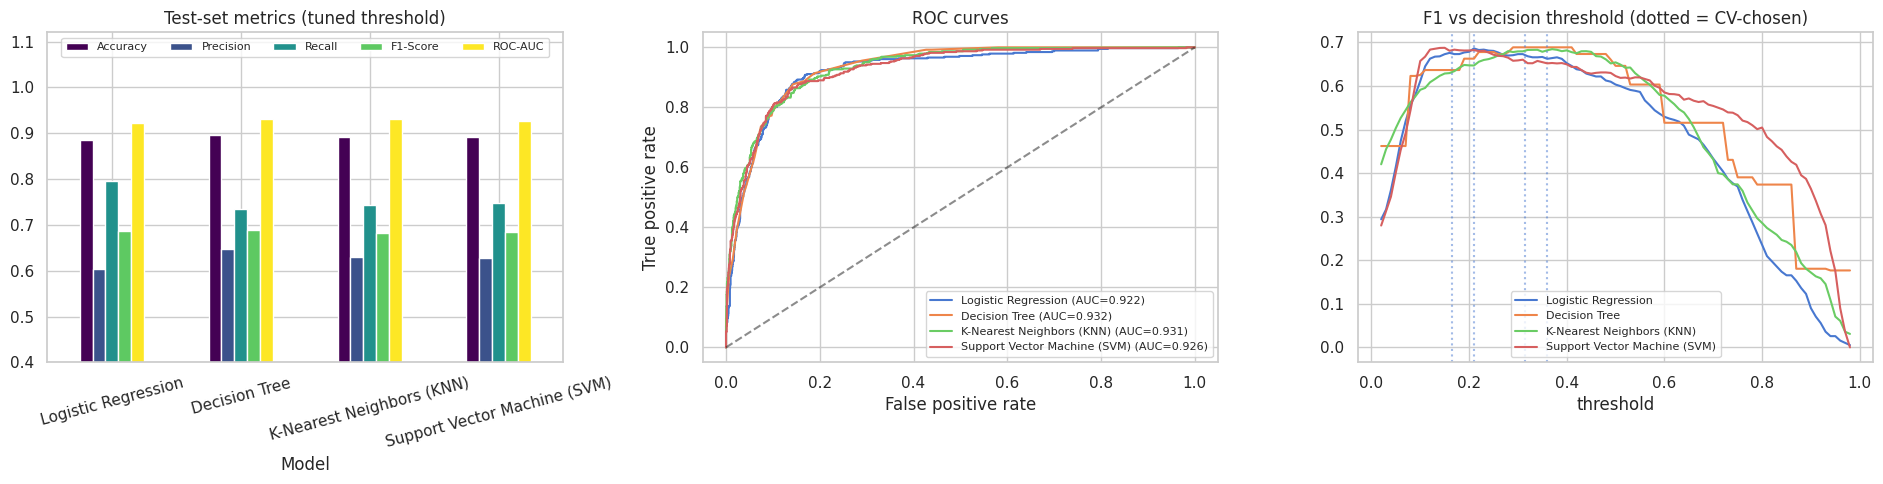

In [15]:
fig, ax = plt.subplots(1, 3, figsize=(19, 5))

# metric comparison
results_df[["Accuracy", "Precision", "Recall", "F1-Score", "ROC-AUC"]].plot.bar(ax=ax[0], rot=15, colormap="viridis")
ax[0].set_ylim(0.4, 1.12); ax[0].set_title("Test-set metrics (tuned threshold)"); ax[0].legend(fontsize=8, ncol=5, loc="upper center")

# ROC curves
for n in models:
    fpr, tpr = roc_curve(y_test, prob[n])
    ax[1].plot(fpr, tpr, label=f"{n} (AUC={roc_auc_score(y_test, prob[n]):.3f})")
ax[1].plot([0, 1], [0, 1], "k--", alpha=.5); ax[1].set_title("ROC curves")
ax[1].set_xlabel("False positive rate"); ax[1].set_ylabel("True positive rate"); ax[1].legend(fontsize=8)

# F1 vs threshold (test, for illustration of the precision/recall trade-off)
grid = np.linspace(0.02, 0.98, 97)
for n in models:
    ax[2].plot(grid, [f1_score(y_test, (prob[n] >= g).astype(int)) for g in grid], label=n)
    ax[2].axvline(models[n].threshold_, ls=":", alpha=.5)
ax[2].set_title("F1 vs decision threshold (dotted = CV-chosen)"); ax[2].set_xlabel("threshold"); ax[2].legend(fontsize=8)
plt.tight_layout(); plt.show()

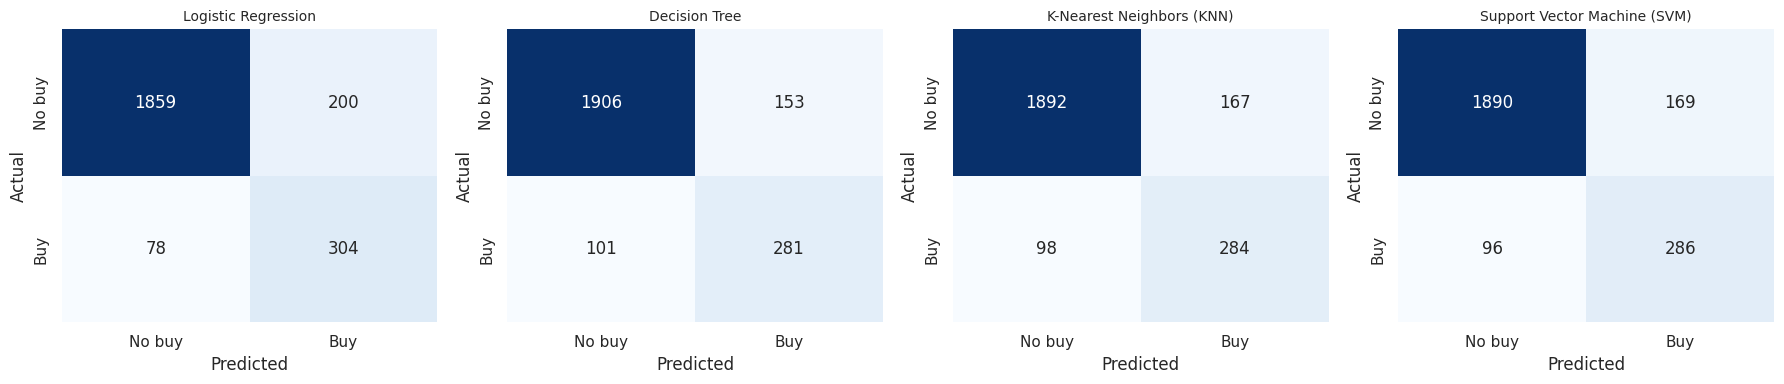

In [16]:
fig, ax = plt.subplots(1, 4, figsize=(18, 4))
for a, (n, m) in zip(ax, models.items()):
    cm = confusion_matrix(y_test, m.predict(X_test))
    sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", cbar=False, ax=a,
                xticklabels=["No buy", "Buy"], yticklabels=["No buy", "Buy"])
    a.set_title(n, fontsize=10); a.set_xlabel("Predicted"); a.set_ylabel("Actual")
plt.tight_layout(); plt.show()

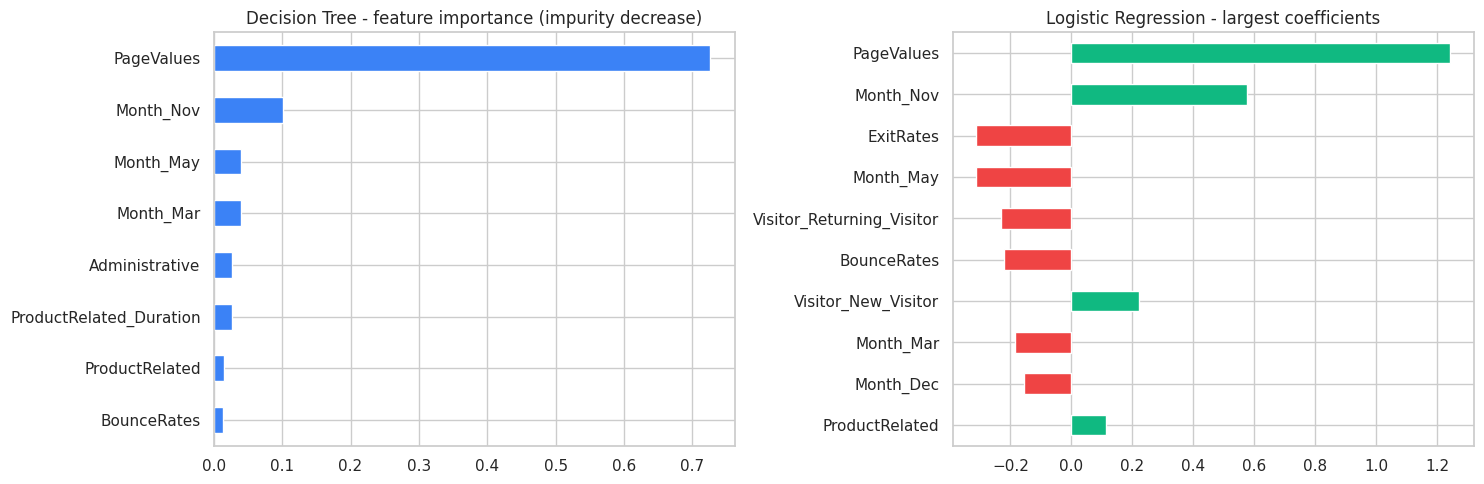

Decision tree depth: 5 | leaves: 28


In [17]:
# Interpretability: what drives the predictions?
names = pre.feature_names_
fig, ax = plt.subplots(1, 2, figsize=(15, 5))

imp = pd.Series(models["Decision Tree"].importances_, index=names).sort_values().tail(8)
imp.plot.barh(ax=ax[0], color="#3B82F6"); ax[0].set_title("Decision Tree - feature importance (impurity decrease)")

coef = pd.Series(models["Logistic Regression"].coef_, index=names)
coef = coef.reindex(coef.abs().sort_values().tail(10).index)
coef.plot.barh(ax=ax[1], color=["#EF4444" if c < 0 else "#10B981" for c in coef]); ax[1].set_title("Logistic Regression - largest coefficients")
plt.tight_layout(); plt.show()

dt = models["Decision Tree"]
print("Decision tree depth:", dt.get_depth(), "| leaves:", dt.get_n_leaves())

## 8. Correctness check against scikit-learn (reference only)
To show the scratch implementations are *correct* and not just plausible, each one is trained with a fixed, untuned configuration and compared with the scikit-learn model of the same configuration on the same split (default 0.5 threshold). scikit-learn is used **only here**; nothing above or in the app depends on it.

In [18]:
from sklearn.linear_model import LogisticRegression as SkLR
from sklearn.tree import DecisionTreeClassifier as SkDT
from sklearn.neighbors import KNeighborsClassifier as SkKNN
from sklearn.svm import SVC as SkSVC
from sklearn.metrics import roc_auc_score as sk_auc

pairs = {
    "Logistic Regression": (LogisticRegressionScratch(l2=1.0), SkLR(C=1.0, max_iter=5000)),
    "Decision Tree":       (DecisionTreeScratch(max_depth=5, min_samples_split=10, min_samples_leaf=5),
                            SkDT(max_depth=5, min_samples_split=10, min_samples_leaf=5, random_state=0)),
    "KNN (k=15)":          (KNNScratch(k=15), SkKNN(n_neighbors=15)),
    "SVM (RBF)":           (SVMScratch(C=1.0, gamma=0.05, n_iter=300), SkSVC(C=1.0, gamma=0.05)),
}
rows = []
for n, (mine, ref) in pairs.items():
    mine.fit(X_train, y_train); ref.fit(X_train, y_train)
    s_ref = ref.decision_function(X_test) if n.startswith("SVM") else ref.predict_proba(X_test)[:, 1]
    p_mine = (mine.score(X_test) > 0).astype(int) if n.startswith("SVM") else (mine.score(X_test) >= 0.5).astype(int)
    p_ref = ref.predict(X_test)
    rows.append({"Model": n,
                 "Acc scratch": accuracy_score(y_test, p_mine), "Acc sklearn": accuracy_score(y_test, p_ref),
                 "F1 scratch": f1_score(y_test, p_mine), "F1 sklearn": f1_score(y_test, p_ref),
                 "AUC scratch": roc_auc_score(y_test, mine.score(X_test)), "AUC sklearn": sk_auc(y_test, s_ref)})
cmp_df = pd.DataFrame(rows).set_index("Model")
display(cmp_df.round(4))
print("Largest accuracy gap: %.4f | largest AUC gap: %.4f" % (
    (cmp_df["Acc scratch"] - cmp_df["Acc sklearn"]).abs().max(),
    (cmp_df["AUC scratch"] - cmp_df["AUC sklearn"]).abs().max()))

,Acc scratch,Acc sklearn,F1 scratch,F1 sklearn,AUC scratch,AUC sklearn
Model,,,,,,
Logistic Regression,0.8972,0.8972,0.6303,0.6303,0.9220,0.9222
Decision Tree,0.9013,0.9013,0.6275,0.6275,0.9264,0.9264
KNN (k=15),0.8980,0.8980,0.6428,0.6428,0.9167,0.9169
SVM (RBF),0.8951,0.9045,0.6484,0.6528,0.9246,0.9165


Largest accuracy gap: 0.0094 | largest AUC gap: 0.0081


## 9. Results & justification

**Final test-set results (tuned threshold, 2,441 unseen sessions, 382 purchases)**

| Model | Accuracy | Precision | Recall | F1 | ROC-AUC |
|---|---|---|---|---|---|
| Logistic Regression | 88.61 % | 60.32 % | 79.58 % | 68.62 % | 92.21 % |
| **Decision Tree** | **89.59 %** | **64.75 %** | 73.56 % | **68.87 %** | **93.17 %** |
| K-Nearest Neighbours | 89.14 % | 62.97 % | 74.35 % | 68.19 % | 93.13 % |
| Support Vector Machine | 89.14 % | 62.86 % | 74.87 % | 68.34 % | 92.61 % |

**Why these numbers are trustworthy**
* **Beats the baseline for real.** Always predicting "no purchase" gives 84.35 % accuracy; all four models are 4-5 points above it and reach ROC-AUC of 0.92-0.93, i.e. they genuinely rank buyers above non-buyers.
* **No leakage.** Duplicates were removed before splitting, scaling/encoding statistics come from the training part only, and hyper-parameters and thresholds were chosen by cross-validation on the training part. The test set was used once.
* **Accuracy is not the whole story.** At the default 0.5 cut-off recall was only 52-63 %, i.e. up to half of the real buyers were missed. Tuning the threshold lifted recall to 74-80 % and F1 from 60-65 % to 68-69 %, while accuracy stayed within about one point (the Decision Tree's accuracy even went up). For an e-commerce use case, finding likely buyers is worth more than a point of accuracy.
* **Implementations are correct.** Logistic Regression, Decision Tree and KNN reproduce scikit-learn's accuracy and F1 exactly on the same configuration (AUC differs by at most 0.0002). The SVM uses a Random-Fourier-Feature approximation of the RBF kernel, so it is not bit-identical to `SVC`, but it is within one accuracy point and has a slightly higher AUC.

**Reading the comparison**
* The Decision Tree is the best model on accuracy, precision, F1 and AUC; Logistic Regression has the highest recall (it flags the most buyers, at the cost of more false alarms).
* The four models are very close (F1 within 0.7 points). With only 382 positive test cases, gaps of 1-2 points are within sampling noise, so the honest conclusion is "all four perform similarly; the Decision Tree is marginally best and the most interpretable".
* All models show the same ceiling (AUC about 0.93): with only these 11 session-level features (no customer history), purchase intent is largely explained by `PageValues`, `ExitRates` and the month.

**Limitations / future work:** single train/test split (repeat with several seeds for confidence intervals), exact kernel SVM via SMO on a subsample, and extra features (traffic source, device, region) that the app does not currently expose.